In [ ]:
import json
import os

import gc_utils
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from scipy.ndimage import gaussian_filter1d

# plt.rc("font", family="Nimbus Roman")
plt.rc("font", family="Nimbus Roman No9 L")

SMALL_SIZE = 7
MEDIUM_SIZE = 7
BIGGER_SIZE = 7

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [ ]:
sim_lst = ["m12b", "m12c", "m12f", "m12i", "m12m"]

sim_dir = "/Users/z5114326/Documents/simulations/"
# sim_dir = "/Volumes/Expansion/simulations/"


scmap = plt.get_cmap("tab10")
colors = [scmap(i) for i in np.linspace(0, 1, len(sim_lst))]
sim_colors = {sim: colors[i] for i, sim in enumerate(sim_lst)}

snap = 600
min_mass = 1e4

sim_halt_path = "../data/sim_data/sim_halt_dict.json"

In [ ]:
public_snapshot_file = sim_dir + "snapshot_times_public.txt"
pub_data = pd.read_table(public_snapshot_file, comment="#", header=None, sep=r"\s+")
pub_data.columns = [
    "index",
    "scale_factor",
    "redshift",
    "time_Gyr",
    "lookback_time_Gyr",
    "time_width_Myr",
]
timez0 = float(pub_data[pub_data["index"] == snap]["time_Gyr"].values[0])
pub_snaps = np.array(pub_data["index"])

all_data_fil = sim_dir + "/" + "m12i" + "/" + "m12i" + "_res7100/" + "snapshot_times.txt"
all_data = pd.read_table(all_data_fil, comment="#", header=None, sep=r"\s+")
all_data.columns = [
    "index",
    "scale_factor",
    "redshift",
    "time_Gyr",
    "lookback_time_Gyr",
    "time_width_Myr",
]
all_times = np.array(all_data["time_Gyr"])
all_snaps = np.array(all_data["index"])

snap_times = {
    gc_utils.snapshot_name(s): float(pub_data.loc[pub_data["index"] == s, "time_Gyr"].values[0])
    for s in pub_snaps
}

sim_codes = sim_dir + "simulation_codes.json"
with open(sim_codes) as sim_json:
    sim_data = json.load(sim_json)

dat_dir = "../data/"
mw_gcs_fil = "mw_gcs/mw_gcs.csv"
mw_gcs = pd.read_csv(dat_dir + mw_gcs_fil)

mw_gcs_cols_fil = "mw_gcs/mw_gcs_colors_ref.csv"
mw_gcs_cols = pd.read_csv(dat_dir + mw_gcs_cols_fil)

mw_gc_class = "../data/mw_gcs/class_chen.txt"
mw_class = pd.read_csv(mw_gc_class, sep=r"\s+")

mw_class.loc[mw_class["Cluster"] == "ESO-SC06", "Cluster"] = "ESO_280-SC06"
mw_class.loc[mw_class["Cluster"] == "1636-283", "Cluster"] = "ESO_452-SC11"

mw_class = mw_class.rename(columns={"Cluster": "cluster_name"})

# Functions

In [ ]:
def build_mass_interpolators(dat):
    interps = []

    for m, t in zip(dat["m_snp"], dat["t_snp"]):
        msk = np.isfinite(m) & (m > 0)
        if np.sum(msk) < 2:
            interps.append(None)
            continue

        order = np.argsort(t[msk])
        ts = t[msk][order]
        ms = m[msk][order]

        interps.append(interp1d(ts, ms, kind="linear", bounds_error=False, fill_value=(ms[0], 0.0)))

    return interps


def halo_mvir_history(halt, halo_tid0, slst):
    """Return Mvir(t) for a halo tracked over snapshots."""
    mvir = []
    for snp in slst:
        tid = gc_utils.get_halo_prog_at_snap(halt, halo_tid0, snp)
        idx = np.where(halt["tid"] == tid)[0][0]
        mvir.append(halt["mass.vir"][idx])
    return np.asarray(mvir)


def gc_counts_and_mass(tim, select, t_snp, m_snp):
    masses = []
    for i in np.where(select)[0]:
        x = t_snp[i]
        y = m_snp[i]
        mask = np.isfinite(x) & np.isfinite(y)
        if mask.sum() >= 2:
            masses.append(np.interp(tim, x[mask], y[mask]))
    return np.sum(select), np.nansum(masses)


def get_gc_prop(sim, sim_dict, halt, host_tid, tims):
    """
    Compute GC count and mass evolution averaged over iterations,
    plus pre-accretion group properties and halo Mvir histories.
    """

    # --- shared time grid ---
    # tlst_start = np.arange(2, 14, 0.5)
    idxs = np.abs(all_times[:, None] - tims).argmin(axis=0)
    tlst = all_times[idxs]
    slst = all_snaps[idxs]

    # --- host halo virial-mass history ---
    host_mvir = halo_mvir_history(halt, host_tid, slst)

    it_ids = list(sim_dict[sim].keys())

    # ==========================================================================
    # ALL GCs (in MW)
    # ==========================================================================
    gccnts_all = []
    gcmass_all = []

    for it_id in it_ids:
        dat = sim_dict[sim][it_id]

        tfor = dat["tfor"]
        tdis = dat["tdis"].copy()
        tdis[tdis == -1] = np.inf
        tacc = dat["tacc"]

        t_snp = dat["t_snp"]
        m_snp = dat["m_snp"]

        cnt = np.zeros(len(tlst))
        mas = np.zeros(len(tlst))

        for k, tim in enumerate(tlst):
            alive = (tfor <= tim) & (tim < tdis)
            inmw = tacc <= tim
            select = alive & inmw

            cnt[k], mas[k] = gc_counts_and_mass(tim, select, t_snp, m_snp)

        gccnts_all.append(cnt)
        gcmass_all.append(mas)

    gccnts_all = np.asarray(gccnts_all)
    gcmass_all = np.asarray(gcmass_all)

    # averages over iterations
    gccnts_mean = gccnts_all.mean(axis=0)
    gccnts_std = gccnts_all.std(axis=0)
    gcmass_mean = gcmass_all.mean(axis=0)
    gcmass_std = gcmass_all.std(axis=0)

    # ==========================================================================
    # OUTPUT
    # ==========================================================================
    return {
        "time": tlst,
        "mvir": host_mvir,
        "cnt_avg": gccnts_mean,
        "cnt_std": gccnts_std,
        "mas_avg": gcmass_mean,
        "mas_std": gcmass_std,
    }


def to_json_serializable(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, dict):
        return {k: to_json_serializable(v) for k, v in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [to_json_serializable(v) for v in obj]
    elif isinstance(obj, (np.integer, np.floating)):
        return obj.item()
    else:
        return obj

In [15]:
def plot_gc_cnt(
    ax,
    sim,
    tim,
    sim_halt_dict,
    sim_colors,
    mw_gcs,
    plt_to=False,
    smoothing=False,
    labels=True,
    return_to=False,
):
    gc_prop_dict = sim_halt_dict[sim]

    # Convert JSON-loaded lists → NumPy arrays
    tim_lst = np.asarray(gc_prop_dict["time"], dtype=float)
    mvirs_all = np.asarray(gc_prop_dict["mvir"], dtype=float)
    gccnts_all = np.asarray(gc_prop_dict["cnt_avg"], dtype=float)

    tmsk = tim_lst <= tim

    mvirs = mvirs_all[tmsk]
    gccnts_mean = gccnts_all[tmsk]

    # SMOOTHING ########################################

    mask = np.isfinite(mvirs) & np.isfinite(gccnts_mean) & (gccnts_mean > 0) & (mvirs > 0)

    logM = np.log10(mvirs[mask])
    logNgc = np.log10(gccnts_mean[mask])
    time_v = tim_lst[tmsk][mask]

    order = np.argsort(logM)
    logM, logNgc, time_v = logM[order], logNgc[order], time_v[order]

    # logM_fine = np.linspace(logM.min(), logM.max(), 300)
    logM_fine = np.linspace(logM.min(), logM.max(), 1000)

    fNgc = interp1d(logM, logNgc, kind="linear", fill_value="extrapolate")
    ftime = interp1d(logM, time_v, kind="linear", fill_value=np.nan)

    logNgc_fine = fNgc(logM_fine)
    logNgc_smooth = gaussian_filter1d(logNgc_fine, sigma=1)

    # Convert back to linear
    M_smooth = 10**logM_fine
    Ngc_smooth = 10**logNgc_smooth

    # M_smooth = np.append(M_smooth, mvirs[-1])
    # Ngc_smooth = np.append(Ngc_smooth, gccnts_mean[-1])

    ####################################################

    if labels:
        label = sim
    else:
        label = None

    if smoothing:
        ax.plot(M_smooth, Ngc_smooth, c=sim_colors[sim], lw=1, label=label)
        if len(mvirs) > 0:
            ax.scatter(M_smooth[-1], Ngc_smooth[-1], color=sim_colors[sim], s=20)
    else:
        ax.plot(mvirs, gccnts_mean, c=sim_colors[sim], lw=1, label=label)
        if len(mvirs) > 0:
            ax.scatter(mvirs[-1], gccnts_mean[-1], color=sim_colors[sim], s=20)

    logx = np.arange(5, 16.5, 0.5)
    x = 10**logx

    # Burkert & Forbes 2020
    # logy = -9.58 + 0.99 * logx
    # y = 10**logy

    # Chen & Gnedin 2023
    x12 = x * 1e-12
    logx12 = np.log10(x12)
    logy = 2.20 + 0.77 * logx12
    y = 10**logy

    ax.plot(x, y, c="k", zorder=0, lw=0.75, ls="--")

    ax.set_xlim(10**10, 10**13)
    ax.set_ylim(0.5 * 10**0, 10**5)

    # Milky Way
    mw_vir = 1.3e12
    ax.scatter(mw_vir, len(mw_gcs), marker="*", c="magenta", s=40)

    ax.set_xscale("log")
    ax.set_yscale("log")

    idx = np.nanargmax(logNgc_smooth)
    to = np.round(ftime(logM_fine[idx]), 2)
    print(sim, "- GC Count Turn-off -", to)
    if plt_to:
        ax.axvline(10.0 ** logM_fine[idx], c=sim_colors[sim], ls=":", zorder=0, lw=0.75)

    if return_to:
        return to


def plot_gc_mas(
    ax,
    sim,
    tim,
    sim_halt_dict,
    sim_colors,
    mw_gcs,
    plt_to=False,
    smoothing=False,
    labels=True,
    return_to=False,
):
    gc_prop_dict = sim_halt_dict[sim]

    # Convert JSON-loaded lists → NumPy arrays
    tim_lst = np.asarray(gc_prop_dict["time"])
    mvirs_all = np.asarray(gc_prop_dict["mvir"])
    gcmas_all = np.asarray(gc_prop_dict["mas_avg"])

    tmsk = tim_lst <= tim

    mvirs = mvirs_all[tmsk]
    gcmas_mean = gcmas_all[tmsk]

    # SMOOTHING ########################################

    mask = np.isfinite(mvirs) & np.isfinite(gcmas_mean) & (gcmas_mean > 0) & (mvirs > 0)

    logM = np.log10(mvirs[mask])
    logMgc = np.log10(gcmas_mean[mask])
    time_v = tim_lst[tmsk][mask]

    order = np.argsort(logM)
    logM, logMgc, time_v = logM[order], logMgc[order], time_v[order]

    # logM_fine = np.linspace(logM.min(), logM.max(), 300)
    logM_fine = np.linspace(logM.min(), logM.max(), 1000)

    fMgc = interp1d(logM, logMgc, kind="linear", fill_value="extrapolate")
    ftime = interp1d(logM, time_v, kind="linear", fill_value=np.nan)

    logMgc_fine = fMgc(logM_fine)
    logMgc_smooth = gaussian_filter1d(logMgc_fine, sigma=1)

    # Convert back to linear
    M_smooth = 10**logM_fine
    Mgc_smooth = 10**logMgc_smooth

    # M_smooth = np.append(M_smooth, mvirs[-1])
    # Mgc_smooth = np.append(Mgc_smooth, gcmas_mean[-1])

    ####################################################

    if labels:
        label = sim
    else:
        label = None

    if smoothing:
        ax.plot(M_smooth, Mgc_smooth, c=sim_colors[sim], lw=1, label=label)
        if len(mvirs) > 0:
            ax.scatter(M_smooth[-1], Mgc_smooth[-1], color=sim_colors[sim], s=20)
    else:
        ax.plot(mvirs, gcmas_mean, c=sim_colors[sim], lw=1, label=label)
        if len(mvirs) > 0:
            ax.scatter(mvirs[-1], gcmas_mean[-1], color=sim_colors[sim], s=20)

    logx = np.arange(5, 16.5, 0.5)
    x = 10**logx

    # Chen & Gnedin 2023
    x12 = x * 1e-12
    logx12 = np.log10(x12)
    logy = 7.45 + 0.93 * logx12
    y = 10**logy

    ax.plot(x, y, c="k", zorder=0, lw=0.75, ls="--")

    ax.set_xlim(1e10, 1e13)
    ax.set_ylim(1e5, 1e10)

    # Milky Way
    mw_vir = 1.3e12
    ax.scatter(mw_vir, np.sum(mw_gcs["mass"]), marker="*", c="magenta", s=40)

    ax.set_xscale("log")
    ax.set_yscale("log")

    idx = np.nanargmax(logMgc_smooth)
    to = np.round(ftime(logM_fine[idx]), 2)
    print(sim, "- GC Mass Turn-off -", to)
    if plt_to:
        ax.axvline(10.0 ** logM_fine[idx], c=sim_colors[sim], ls=":", zorder=0, lw=0.75)

    if return_to:
        return to

# Calculations

In [ ]:
# ------------------------------------------------------------------
# time grid
dt = 0.2
tims = np.arange(0.4, timez0, dt)
tims = np.append(tims, timez0)

In [ ]:
sim_dict = {}

# ------------------------------------------------
# precompute snapshot times once
# ------------------------------------------------
snap_times = {
    gc_utils.snapshot_name(s): float(pub_data.loc[pub_data["index"] == s, "time_Gyr"].values[0])
    for s in pub_snaps
}

timez0 = snap_times[gc_utils.snapshot_name(snap)]

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    sim_dict[sim] = {}

    with h5py.File(ghost_file, "r") as ghost_data:
        for it_id, it_grp in ghost_data.items():
            src = it_grp["source"]

            # ---------------------------
            # read once
            # ---------------------------
            grpid = src["grpid"][()]
            amsk = grpid == 0

            logm_tfor = src["logm_tfor"][()]
            logm_tz0 = src["logm_tz0"][()]

            m_tfo = 10.0**logm_tfor
            m_tfo_ev = 0.55 * m_tfo  # stellar-evolution corrected mass

            m_tz0 = np.zeros_like(logm_tz0, dtype=float)
            msk = logm_tz0 != -1
            m_tz0[msk] = 10.0 ** logm_tz0[msk]

            tfor = src["tfor"][()]
            tdis = src["tdis"][()]
            tacc = src["tacc"][()]
            gcids = src["gcid"][()]

            # ---------------------------
            # snapshot mass table
            #   + tfor (m_tfo_ev)
            #   + tdis (0)
            # ---------------------------
            n_gc = len(gcids)
            n_snap = len(pub_snaps)

            mass_arr = np.full((n_gc, n_snap + 2), np.nan)
            time_arr = np.full((n_gc, n_snap + 2), np.nan)

            # ---- formation point ----
            mass_arr[:, 0] = m_tfo_ev
            time_arr[:, 0] = tfor

            # ---- simulation snapshots ----
            for j, (snap_id, time) in enumerate(snap_times.items(), start=1):
                snp = it_grp["snapshots"][snap_id]
                snp_gcids = snp["gcid"][()]
                snp_mass = 10.0 ** snp["logm"][()]

                common, idx_snp, idx_src = np.intersect1d(snp_gcids, gcids, return_indices=True)

                mass_arr[idx_src, j] = snp_mass[idx_snp]
                time_arr[idx_src, j] = time

                # ---- disruption point (only if disrupted) ----
                has_disrupted = np.isfinite(tdis)

                mass_arr[has_disrupted, -1] = 0.0
                time_arr[has_disrupted, -1] = tdis[has_disrupted]

            # ---------------------------
            # final mass cut
            # ---------------------------
            m_tfo_msk = m_tfo >= min_mass

            sim_dict[sim][it_id] = {
                "tfor": tfor[m_tfo_msk],
                "tdis": tdis[m_tfo_msk],
                "tacc": tacc[m_tfo_msk],
                "acc": amsk[m_tfo_msk],
                # ---- time-resolved mass history ----
                "m_snp": mass_arr[m_tfo_msk],
                "t_snp": time_arr[m_tfo_msk],
            }

for sim in sim_lst:
    for it_id in sim_dict[sim]:
        sim_dict[sim][it_id]["mass_interp"] = build_mass_interpolators(sim_dict[sim][it_id])

In [ ]:
# --------------------------------------------------
# Load or compute
# --------------------------------------------------
if os.path.exists(sim_halt_path):
    print("Loading existing sim_halt_dict JSON...")
    with open(sim_halt_path, "r", encoding="utf-8") as f:
        sim_halt_dict = json.load(f)

else:
    print("JSON not found — computing sim_halt_dict...")
    sim_halt_dict = {sim: None for sim in sim_lst}

    for sim in sim_lst:
        print(sim)
        halt = gc_utils.get_halo_tree(sim, sim_dir)
        host_tid = sim_data[sim]["halo"]

        gc_prop_dict = get_gc_prop(sim, sim_dict, halt, host_tid, tims)
        sim_halt_dict[sim] = gc_prop_dict

        del halt

    # Convert NumPy objects → JSON-safe
    sim_halt_dict_json = to_json_serializable(sim_halt_dict)

    # Save
    with open(sim_halt_path, "w", encoding="utf-8") as f:
        json.dump(sim_halt_dict_json, f, indent=4)

    print("Saved sim_halt_dict JSON.")

m12b - GC Count Turn-off - 3.2
m12b - GC Mass Turn-off - 3.21

m12c - GC Count Turn-off - 4.44
m12c - GC Mass Turn-off - 4.41

m12f - GC Count Turn-off - 3.21
m12f - GC Mass Turn-off - 3.21

m12i - GC Count Turn-off - 5.2
m12i - GC Mass Turn-off - 5.2

m12m - GC Count Turn-off - 3.9
m12m - GC Mass Turn-off - 4.45



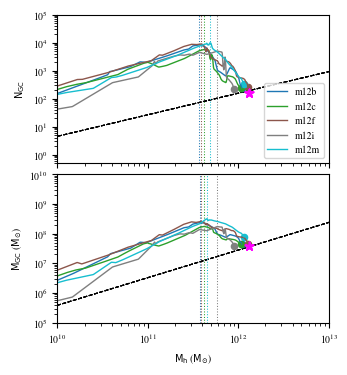

In [16]:
# fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(8, 10))
fig, axs = plt.subplots(2, 1, figsize=(3.5, 4.0))
plt.subplots_adjust(hspace=0.075)

to_dict_lbt = {"cnt": {sim: None for sim in sim_lst}, "mas": {sim: None for sim in sim_lst}}

tim_z00 = timez0
for sim in sim_lst:
    to_cnt = plot_gc_cnt(
        axs[0], sim, tim_z00, sim_halt_dict, sim_colors, mw_gcs, plt_to=True, smoothing=True, return_to=True
    )
    to_mas = plot_gc_mas(
        axs[1], sim, tim_z00, sim_halt_dict, sim_colors, mw_gcs, plt_to=True, smoothing=True, return_to=True
    )

    to_dict_lbt["cnt"][sim] = np.round(timez0 - to_cnt, 3)
    to_dict_lbt["mas"][sim] = np.round(timez0 - to_mas, 3)

    print()

# axs[0].set_xlim(10**8)

axs[1].set_xlabel(r"$\mathrm{M_{\rm h}}$ ($\mathrm{M_{\odot}}$)")
axs[0].set_xticklabels([])

axs[0].set_ylabel(r"$\mathrm{N_{GC}}$")
axs[1].set_ylabel(r"$\mathrm{M_{GC}}$ ($\mathrm{M_{\odot}}$)")

axs[0].legend(loc="lower right", ncols=1)

to_path = "../data/sim_data/turn_offs_lbt.json"
with open(to_path, "w", encoding="utf-8") as f:
    json.dump(to_dict_lbt, f, indent=4)

save_name = "../data/figures/galaxy_plots/turn_offs.pdf"
fig.savefig(save_name)
plt.show()